In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
ds = pd.read_csv('ObesityDataSet_raw_and_data_sinthetic.csv')
ds.head()

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


In [3]:
np.unique('NObeyesdad')

array(['NObeyesdad'], dtype='<U10')

In [4]:
ds['NObeyesdad'].unique()

array(['Normal_Weight', 'Overweight_Level_I', 'Overweight_Level_II',
       'Obesity_Type_I', 'Insufficient_Weight', 'Obesity_Type_II',
       'Obesity_Type_III'], dtype=object)

In [5]:
category = {
    'Normal_Weight': 0,
    'Overweight_Level_I': 1,
    'Overweight_Level_II': 2,
    'Obesity_Type_I': 3,
    'Insufficient_Weight': 4,
    'Obesity_Type_II': 5,
    'Obesity_Type_III': 6
}

In [6]:
ds['NObeyesdad'] = ds['NObeyesdad'].map(category)

In [7]:
ds.head()

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,0
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,0
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,0
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,1
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,2


In [8]:
print (ds.dtypes)

Gender                             object
Age                               float64
Height                            float64
Weight                            float64
family_history_with_overweight     object
FAVC                               object
FCVC                              float64
NCP                               float64
CAEC                               object
SMOKE                              object
CH2O                              float64
SCC                                object
FAF                               float64
TUE                               float64
CALC                               object
MTRANS                             object
NObeyesdad                          int64
dtype: object


In [9]:
for col in ds.select_dtypes(include=['object']).columns:
    ds[col] = ds[col].astype('category').cat.codes  

ds = ds.astype(int)

print(ds.dtypes)

Gender                            int64
Age                               int64
Height                            int64
Weight                            int64
family_history_with_overweight    int64
FAVC                              int64
FCVC                              int64
NCP                               int64
CAEC                              int64
SMOKE                             int64
CH2O                              int64
SCC                               int64
FAF                               int64
TUE                               int64
CALC                              int64
MTRANS                            int64
NObeyesdad                        int64
dtype: object


In [10]:
y = ds['NObeyesdad'].values.reshape(-1,1) 

In [11]:
X = ds['Weight'].values.reshape(-1,1)

In [12]:
X = (X - np.mean(X, axis=0)) / np.std(X, axis=0)

In [13]:
X = np.hstack((np.ones((X.shape[0], 1)), X))

In [1]:
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

In [2]:
def compute_cost(X, y, theta):
    m = len(y)
    h = sigmoid(X @ theta)
    cost = (-1/m) * np.sum(y * np.log(h) + (1 - y) * np.log(1 - h))
    return cost

In [17]:
def gradient_descent(X, y, theta, learning_rate, iterations):
    m = len(y)
    cost_history = []

    for i in range(iterations):
        gradient = (1/m) * (X.T @ (sigmoid(X @ theta) - y))
        theta -= learning_rate * gradient
        cost_history.append(compute_cost(X, y, theta))

        if i % (iterations/10) == 0: 
            print(f"Iteration {i}: Cost {cost_history[-1]:.4f}")

    return theta, cost_history

In [18]:
theta = np.zeros((X.shape[1], 1))
learning_rate = 0.01
iterations = 10

In [19]:
theta, cost_history = gradient_descent(X, y, theta, learning_rate, iterations)

Iteration 0: Cost 0.6123
Iteration 1: Cost 0.5319
Iteration 2: Cost 0.4518
Iteration 3: Cost 0.3722
Iteration 4: Cost 0.2930
Iteration 5: Cost 0.2141
Iteration 6: Cost 0.1357
Iteration 7: Cost 0.0576
Iteration 8: Cost -0.0201
Iteration 9: Cost -0.0974


In [20]:
def predict(X, theta):
    return (sigmoid(X @ theta) >= 0.5).astype(int)

In [25]:
yp = predict(X, theta)

In [26]:
accuracy = np.mean(yp == y) * 100
print(f"Training Accuracy: {accuracy:.2f}%")

Training Accuracy: 13.74%


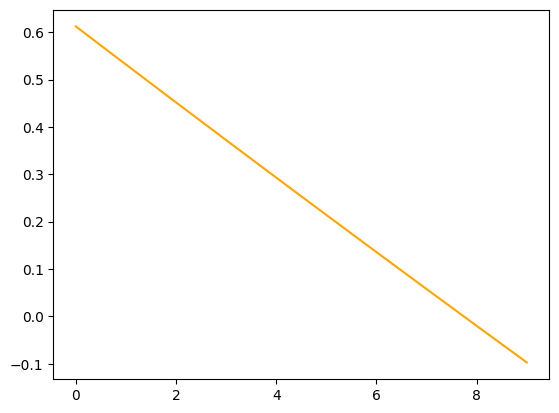

In [24]:
plt.plot(np.arange(iterations), cost_history, c = 'orange')
plt.show()